# 01 · EDA

Measures the numbers that fix three design decisions before any modelling:
who gets a label, where the dataset has to be cut off, and where the
train / validation / test boundaries go.

Run `make data` first. Nothing here feeds the model directly: the dates this
notebook arrives at are recorded in `src/opspilot/config.py` and explained in
`docs/decisions/`.

In [1]:
from datetime import timedelta

import duckdb
import matplotlib.pyplot as plt
import pandas as pd

from opspilot import config

pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:,.2f}".format)

BLUE, INK, MUTED, GRID, SURFACE = "#2a78d6", "#0b0b0b", "#52514e", "#e4e3de", "#fcfcfb"
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "axes.edgecolor": GRID,
        "axes.labelcolor": MUTED,
        "text.color": INK,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.grid.axis": "y",
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "axes.axisbelow": True,
        "axes.titlelocation": "left",
        "axes.titlesize": 10,
        "axes.titleweight": "bold",
        "font.size": 9,
    }
)

TABLES = {
    "orders": "olist_orders_dataset.csv",
    "order_items": "olist_order_items_dataset.csv",
    "customers": "olist_customers_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "products": "olist_products_dataset.csv",
    "payments": "olist_order_payments_dataset.csv",
    "reviews": "olist_order_reviews_dataset.csv",
    "geolocation": "olist_geolocation_dataset.csv",
    "category_translation": "product_category_name_translation.csv",
}

con = duckdb.connect()
for name, file in TABLES.items():
    con.sql(f"create view {name} as select * from read_csv_auto('{config.RAW_DIR / file}')")


def q(sql: str) -> pd.DataFrame:
    return con.sql(sql).df()

## 1. Rows per table

In [2]:
pd.DataFrame(
    [(name, con.sql(f"select count(*) from {name}").fetchone()[0]) for name in TABLES],
    columns=["table", "rows"],
).set_index("table")

,rows
table,
orders,99441
order_items,112650
customers,99441
sellers,3095
products,32951
payments,103886
reviews,99224
geolocation,1000163
category_translation,71


## 2. Order status: who gets a label

Only orders that were actually delivered have an outcome to predict.

In [3]:
q("""
    select order_status,
           count(*) as orders,
           round(100.0 * count(*) / sum(count(*)) over (), 2) as pct,
           count(*) filter (where order_delivered_customer_date is null) as without_delivery_date
    from orders
    group by 1
    order by 2 desc
""")

,order_status,orders,pct,without_delivery_date
0,delivered,96478,97.02,8
1,shipped,1107,1.11,1107
2,canceled,625,0.63,619
3,unavailable,609,0.61,609
4,invoiced,314,0.32,314
5,processing,301,0.30,301
6,created,5,0.01,5
7,approved,2,0.00,2


In [4]:
con.sql("""
    create view labeled as
    select *,
           coalesce(order_approved_at, order_purchase_timestamp) as t0,
           (order_delivered_customer_date::date > order_estimated_delivery_date::date)::int as is_late,
           date_diff('second', order_purchase_timestamp, order_delivered_customer_date) / 86400.0
               as delivery_days,
           date_diff('second', order_purchase_timestamp, order_approved_at) / 3600.0
               as approval_delay_hours
    from orders
    where order_status = 'delivered' and order_delivered_customer_date is not null
""")

n_orders = con.sql("select count(*) from orders").fetchone()[0]
n_labeled = con.sql("select count(*) from labeled").fetchone()[0]
print(f"{n_labeled:,} of {n_orders:,} orders get a label; {n_orders - n_labeled:,} are excluded.")

96,470 of 99,441 orders get a label; 2,971 are excluded.


**Takeaway.** 97% of orders are `delivered`. The label covers delivered orders with a
delivery date; the excluded ones are the non-delivered statuses plus 8 orders marked
delivered with no delivery date.

## 3. Timestamps: ranges and null rates

In [5]:
TIMESTAMPS = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]
q(
    " union all ".join(
        f"""
        select '{c}' as column_name,
               min({c}) as first_value,
               max({c}) as last_value,
               count(*) filter (where {c} is null) as nulls,
               round(100.0 * count(*) filter (where {c} is null) / count(*), 3) as null_pct,
               (select count(*) from labeled where {c} is null) as nulls_among_labeled
        from orders
        """
        for c in TIMESTAMPS
    )
)

,column_name,first_value,last_value,nulls,null_pct,nulls_among_labeled
0,order_purchase_timestamp,2016-09-04 21:15:19,2018-10-17 17:30:18,0,0.00,0
1,order_approved_at,2016-09-15 12:16:38,2018-09-03 17:40:06,160,0.16,14
2,order_delivered_carrier_date,2016-10-08 10:34:01,2018-09-11 19:48:28,1783,1.79,1
3,order_delivered_customer_date,2016-10-11 13:46:32,2018-10-17 13:22:46,2965,2.98,0
4,order_estimated_delivery_date,2016-09-30 00:00:00,2018-11-12 00:00:00,0,0.00,0


**Takeaway.** Purchase and estimated dates are never null. `order_approved_at` is null
for 160 orders but only 14 labeled ones, so the fallback to the purchase timestamp for
t0 is rarely used. Note the last values: approvals stop on 2018-09-03 while one delivery
is recorded as late as 2018-10-17. Section 7 comes back to this.

## 4. The label: late rate

`is_late = 1` when the delivery **date** is after the estimated delivery **date**.

In [6]:
q("""
    select count(*) as labeled_orders,
           count(*) filter (where is_late = 1) as late_orders,
           round(100.0 * avg(is_late), 2) as late_pct_calendar_dates,
           round(
               100.0 * avg((order_delivered_customer_date > order_estimated_delivery_date)::int), 2
           ) as late_pct_raw_timestamps,
           (select count(*) from orders
            where order_estimated_delivery_date::time <> time '00:00:00') as estimates_not_at_midnight
    from labeled
""")

,labeled_orders,late_orders,late_pct_calendar_dates,late_pct_raw_timestamps,estimates_not_at_midnight
0,96470,6534,6.77,8.11,0


**Takeaway.** The late rate is **6.77%**. Every estimated date is stored at midnight, so
comparing raw timestamps would call an order late when it arrives at 15:00 on the promised
day, and would inflate the late rate to 8.11%. Comparing calendar dates is the right
definition.

## 5. Orders and late rate per purchase month

In [7]:
monthly = q("""
    select date_trunc('month', order_purchase_timestamp)::date as purchase_month,
           count(*) as orders,
           count(*) filter (where order_status = 'delivered'
                            and order_delivered_customer_date is not null) as labeled,
           round(100.0 * avg(
               (order_delivered_customer_date::date > order_estimated_delivery_date::date)::int
           ) filter (where order_status = 'delivered'
                     and order_delivered_customer_date is not null), 2) as late_pct
    from orders
    group by 1
    order by 1
""")
monthly.set_index("purchase_month")

,orders,labeled,late_pct
purchase_month,,,
2016-09-01,4,1,100.00
2016-10-01,324,265,0.75
2016-12-01,1,1,0.00
2017-01-01,800,750,2.93
2017-02-01,1780,1653,2.96
2017-03-01,2682,2546,4.56
2017-04-01,2404,2303,6.56
2017-05-01,3700,3545,2.99
2017-06-01,3245,3135,3.03


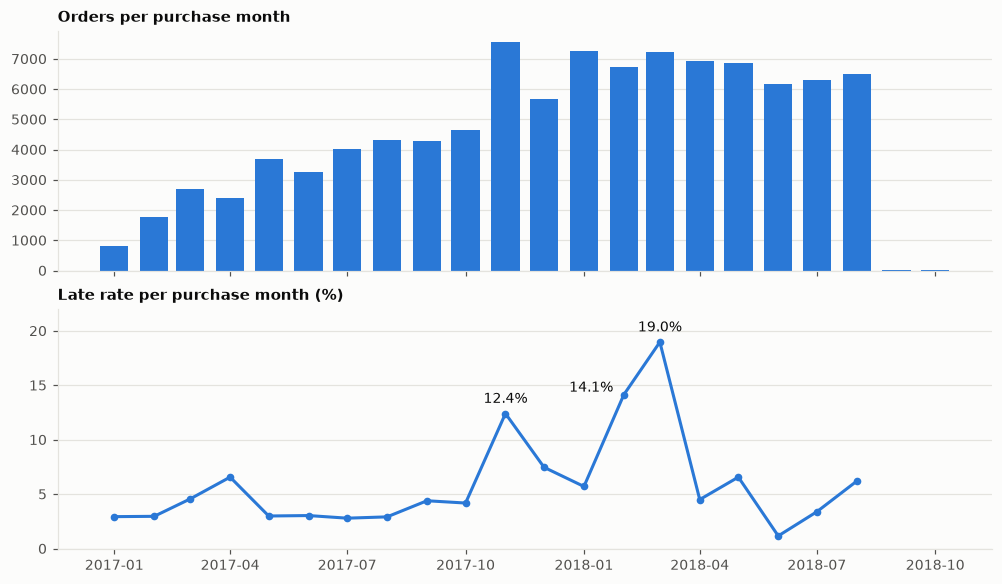

In [8]:
plot = monthly[monthly.purchase_month >= "2017-01-01"]
fig, (ax_n, ax_late) = plt.subplots(2, 1, figsize=(9, 5.2), sharex=True, layout="constrained")

ax_n.bar(plot.purchase_month, plot.orders, width=22, color=BLUE)
ax_n.set_title("Orders per purchase month")

ax_late.plot(plot.purchase_month, plot.late_pct, color=BLUE, linewidth=2, marker="o", markersize=4)
ax_late.set_title("Late rate per purchase month (%)")
ax_late.set_ylim(0, 22)
for month, offset, align in [
    ("2017-11-01", (0, 7), "center"),
    ("2018-02-01", (-7, 2), "right"),
    ("2018-03-01", (0, 7), "center"),
]:
    row = plot[plot.purchase_month == month].iloc[0]
    ax_late.annotate(
        f"{row.late_pct:.1f}%",
        (row.purchase_month, row.late_pct),
        textcoords="offset points",
        xytext=offset,
        ha=align,
    )
plt.show()

**Takeaway.** Volume grows through 2017 and is flat at 6-7k orders a month in 2018. 2016
is almost empty (329 orders, none in November) and the data really starts on 2017-01-05.

The late rate is **not stable**: 3-5% in a typical month, but 12.4% in November 2017
(Black Friday), then 14.1% and 19.0% in February and March 2018. Any chronological split
puts those spikes somewhere, and it matters where.

## 6. Delivery time (purchase to delivery, in days)

In [9]:
days = q("select delivery_days from labeled").delivery_days
p99 = days.quantile(0.99)
days.describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99, 0.999]).to_frame().T

,count,mean,std,min,25%,50%,75%,90%,95%,99%,99.9%,max
delivery_days,"96,470.00",12.56,9.55,0.53,6.77,10.22,15.72,23.10,29.27,46.05,83.14,209.63


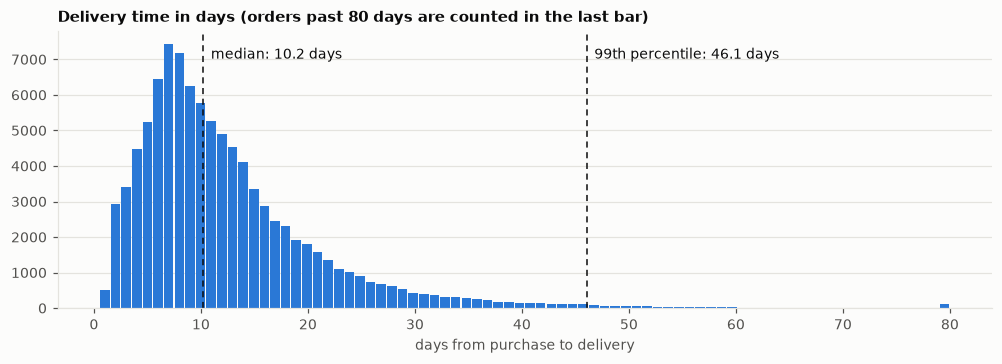

In [10]:
fig, ax = plt.subplots(figsize=(9, 3.2), layout="constrained")
ax.hist(days.clip(upper=80), bins=80, color=BLUE, rwidth=0.9)
for value, label in [(days.median(), "median"), (p99, "99th percentile")]:
    ax.axvline(value, color=INK, linewidth=1, linestyle=(0, (4, 3)))
    ax.annotate(
        f"{label}: {value:.1f} days",
        (value, ax.get_ylim()[1] * 0.9),
        textcoords="offset points",
        xytext=(5, 0),
    )
ax.set_title("Delivery time in days (orders past 80 days are counted in the last bar)")
ax.set_xlabel("days from purchase to delivery")
plt.show()

In [11]:
q("""
    select is_late,
           count(*) as orders,
           round(median(delivery_days), 1) as median_days,
           round(quantile_cont(delivery_days, 0.99), 1) as p99_days,
           round(100.0 * avg((delivery_days > 46)::int), 1) as pct_longer_than_46_days
    from labeled
    group by 1
    order by 1
""")

,is_late,orders,median_days,p99_days,pct_longer_than_46_days
0,0,89936,9.80,30.20,0.00
1,1,6534,31.20,99.70,14.30


**Takeaway.** Half of all orders arrive within 10.2 days and 99% within **46 days**. That
46-day figure is the censoring horizon used in section 7. One caveat to keep in mind:
late orders are the slow tail, and about 14% of them take longer than 46 days, so the
horizon covers 99% of all orders but fewer of the late ones.

## 7. Approval delay and t0

t0 (prediction time) is `order_approved_at`, falling back to the purchase timestamp.

In [12]:
delay = q(
    "select approval_delay_hours from labeled where approval_delay_hours is not null"
).approval_delay_hours
print(
    f"Approved within 1 hour: {100 * (delay < 1).mean():.1f}%   "
    f"after more than 24 hours: {100 * (delay > 24).mean():.1f}%   "
    f"negative delays: {(delay < 0).sum()}"
)
delay.describe(percentiles=[0.5, 0.75, 0.9, 0.99]).to_frame().T

Approved within 1 hour: 64.0%   after more than 24 hours: 17.5%   negative delays: 0


,count,mean,std,min,50%,75%,90%,99%,max
approval_delay_hours,"96,456.00",10.28,20.54,0.00,0.34,14.52,34.59,89.79,741.44


In [13]:
q("""
    select count(*) filter (where order_delivered_carrier_date < t0) as handed_to_carrier_before_t0,
           count(*) filter (where order_delivered_customer_date < t0) as delivered_before_t0,
           count(*) filter (where order_estimated_delivery_date < t0) as estimate_before_t0
    from labeled
""")

,handed_to_carrier_before_t0,delivered_before_t0,estimate_before_t0
0,1350,61,6


**Takeaway.** Approval is usually quick (median 20 minutes, 64% within the hour), but 17.5%
of orders wait more than a day and the slowest waits a month. The approval timestamp is
also not perfectly trustworthy: 1,350 labeled orders (1.4%) were handed to the carrier
before they were "approved", and 61 were delivered before it. Small enough to keep t0 as
planned, but worth recording.

## 8. Censoring: where the data really ends

The plan's rule is: drop orders purchased after *last observed delivery date minus the
99th-percentile delivery time*. The maximum delivery date is 2018-10-17, but look at how
many deliveries are recorded per day near the end.

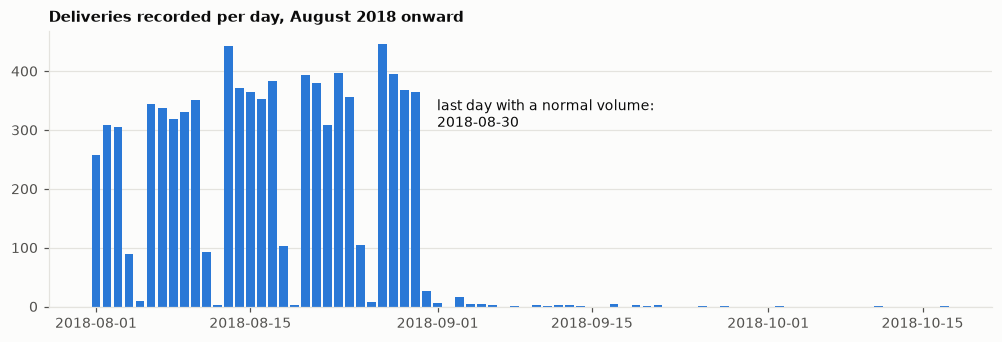

Last day with at least 100 deliveries: 2018-08-30
Deliveries recorded after it: 86 (the last one on 2018-10-17)


In [14]:
daily = q("""
    select order_delivered_customer_date::date as day, count(*) as deliveries
    from orders
    where order_delivered_customer_date is not null
    group by 1
    order by 1
""")
observation_end = daily.loc[daily.deliveries >= 100, "day"].max()

tail = daily[daily.day >= "2018-08-01"]
fig, ax = plt.subplots(figsize=(9, 3), layout="constrained")
ax.bar(tail.day, tail.deliveries, width=0.8, color=BLUE)
ax.annotate(
    f"last day with a normal volume:\n{observation_end:%Y-%m-%d}",
    (observation_end, tail.loc[tail.day == observation_end, "deliveries"].iloc[0]),
    textcoords="offset points",
    xytext=(14, -4),
    va="top",
)
ax.set_title("Deliveries recorded per day, August 2018 onward")
plt.show()

after = int(daily.loc[daily.day > observation_end, "deliveries"].sum())
print(f"Last day with at least 100 deliveries: {observation_end:%Y-%m-%d}")
print(f"Deliveries recorded after it: {after} (the last one on {daily.day.max():%Y-%m-%d})")

Deliveries run at 300-450 per weekday until **2018-08-30** and then stop. The extract was
effectively taken at the end of August; only 86 later deliveries trickled in. Using
2018-10-17 as "the last observed delivery" would keep every order and hide the problem.

The orders purchased in the final weeks show what censoring does:

In [15]:
weekly = q("""
    select date_trunc('week', order_purchase_timestamp)::date as purchase_week,
           count(*) as labeled_orders,
           round(quantile_cont(delivery_days, 0.99), 1) as p99_delivery_days,
           round(100.0 * avg(is_late), 2) as late_pct
    from labeled
    where order_purchase_timestamp >= '2018-05-07'
    group by 1
    order by 1
""")
weekly.set_index("purchase_week")

,labeled_orders,p99_delivery_days,late_pct
purchase_week,,,
2018-05-07,1943,35.90,6.43
2018-05-14,1805,34.90,12.13
2018-05-21,941,33.40,4.04
2018-05-28,1075,36.10,0.37
2018-06-04,1421,35.10,1.27
2018-06-11,1497,35.10,1.74
2018-06-18,1442,32.60,0.97
2018-06-25,1378,29.70,0.73
2018-07-02,1178,30.50,1.44


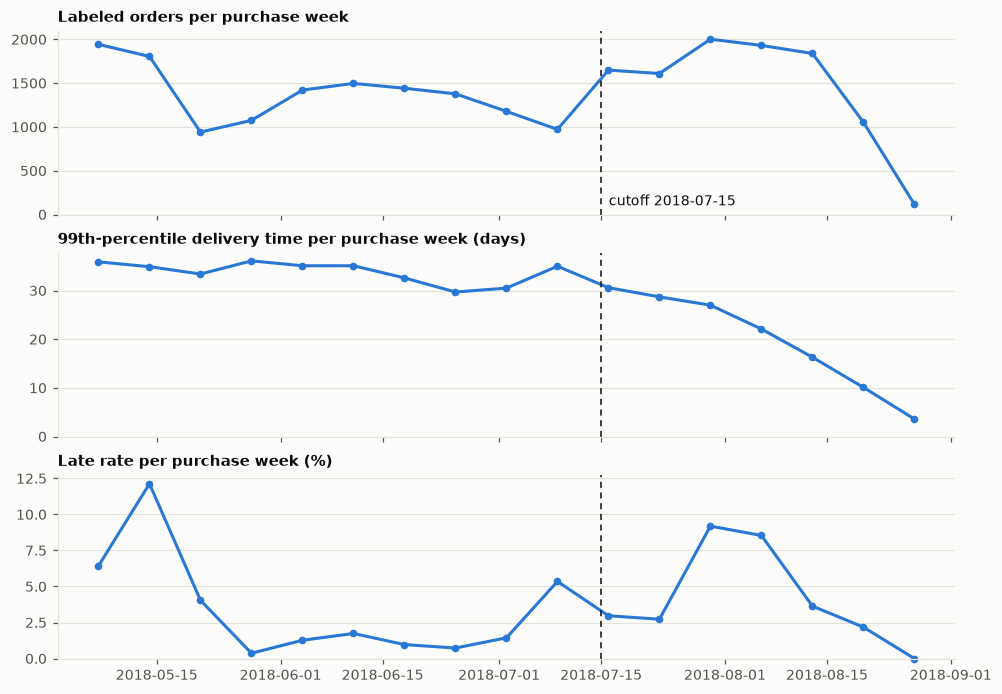

Observation end 2018-08-30 - 46 days = cutoff 2018-07-15


In [16]:
horizon_days = round(p99)
cutoff = observation_end - timedelta(days=horizon_days)

fig, axes = plt.subplots(3, 1, figsize=(9, 6.2), sharex=True, layout="constrained")
panels = [
    ("labeled_orders", "Labeled orders per purchase week"),
    ("p99_delivery_days", "99th-percentile delivery time per purchase week (days)"),
    ("late_pct", "Late rate per purchase week (%)"),
]
for ax, (column, title) in zip(axes, panels, strict=True):
    ax.plot(
        weekly.purchase_week,
        weekly[column],
        color=BLUE,
        linewidth=2,
        marker="o",
        markersize=4,
        clip_on=False,
    )
    ax.axvline(cutoff, color=INK, linewidth=1, linestyle=(0, (4, 3)))
    ax.set_title(title)
    ax.set_ylim(0, None)
axes[0].annotate(
    f"cutoff {cutoff:%Y-%m-%d}",
    (cutoff, 0),
    textcoords="offset points",
    xytext=(5, 6),
)
plt.show()

print(
    f"Observation end {observation_end:%Y-%m-%d} - {horizon_days} days = cutoff {cutoff:%Y-%m-%d}"
)
assert observation_end.date() == config.OBSERVATION_END
assert horizon_days == config.CENSORING_HORIZON_DAYS
assert cutoff.date() == config.CENSORING_CUTOFF

**Takeaway.** After the cutoff the slowest delivery in each week gets steadily shorter,
because only orders that had already arrived by the end of August made it into the data.
The order counts collapse in the last ten days for the same reason, and the late rate of
the final weeks falls toward zero: an order purchased on 20 August and promised for early
September cannot be observed as late. Slow orders are missing, not on time.

**Censoring cutoff: keep orders purchased on or before 2018-07-15** (2018-08-30 minus 46 days).

## 9. The split

Train on 2017, validate on the first quarter of 2018, test on April 2018 up to the cutoff.

In [17]:
split_rows = [
    ("dropped: before 2017 (sparse)", None, config.SPLITS["train"][0] - timedelta(days=1)),
    *[(name, start, end) for name, (start, end) in config.SPLITS.items()],
    ("dropped: after cutoff (censored)", config.CENSORING_CUTOFF + timedelta(days=1), None),
]
splits = pd.concat(
    [
        q(f"""
            select '{name}' as split,
                   min(order_purchase_timestamp)::date as first_purchase,
                   max(order_purchase_timestamp)::date as last_purchase,
                   count(*) as labeled_orders,
                   count(*) filter (where is_late = 1) as late_orders,
                   round(100.0 * avg(is_late), 2) as late_pct
            from labeled
            where order_purchase_timestamp::date >= '{start or "1900-01-01"}'
              and order_purchase_timestamp::date <= '{end or "2100-01-01"}'
        """)
        for name, start, end in split_rows
    ],
    ignore_index=True,
)
kept = splits.split.isin(config.SPLITS)
splits["share_of_kept_pct"] = (
    100 * splits.labeled_orders / splits.labeled_orders[kept].sum()
).where(kept)
splits.set_index("split")

,first_purchase,last_purchase,labeled_orders,late_orders,late_pct,share_of_kept_pct
split,,,,,,
dropped: before 2017 (sparse),2016-09-15,2016-12-23,267,3,1.12,NaN
train,2017-01-05,2017-12-31,43426,2453,5.65,50.49
validation,2018-01-01,2018-03-31,20627,2657,12.88,23.98
test,2018-04-01,2018-07-15,21949,889,4.05,25.52
dropped: after cutoff (censored),2018-07-16,2018-08-29,10201,532,5.22,NaN


**Takeaway.** The split is roughly 50 / 24 / 26 and each part has enough late orders to
measure (the test set has about 890).

The three parts do **not** share a late rate: train 5.7%, validation 12.9%, test 4.1%.
Validation is the anomalous quarter (February and March 2018). That is a real property of
this data and not a leak, but it has consequences for later weeks:

- A calibrator fitted on validation learns a base rate three times the test one, so
  calibrated probabilities are likely to run high on test. Week 5 has to check this.
- PR-AUC depends on the base rate, so validation and test PR-AUC are not comparable
  with each other. Always print the late rate next to it.

## Numbers to remember

| | |
| --- | --- |
| Orders | 99,441 total, **96,470 labeled** (delivered, with a delivery date) |
| Late rate | **6.77%** over all labeled orders (calendar-date comparison) |
| Delivery time | median 10.2 days, 99th percentile **46 days** |
| Observation end | **2018-08-30** (not the 2018-10-17 maximum) |
| Censoring cutoff | keep purchases on or before **2018-07-15** |
| Train | 2017-01-01 to 2017-12-31, late rate 5.7% |
| Validation | 2018-01-01 to 2018-03-31, late rate 12.9% |
| Test | 2018-04-01 to 2018-07-15, late rate 4.1% |